In [1]:
import sys
print(sys.version)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [5]:
!pip install pycaret 

In [6]:
from pycaret.regression import *
print("PyCaret imported successfully!")

PyCaret imported successfully!


In [7]:
import pandas as pd

df = pd.read_csv(r"C:\Users\alluh\Downloads\Housing.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,1485000,1760,2,1,3,yes,no,yes,no,yes,0,no,furnished
1,1918000,4672,3,2,3,yes,yes,yes,yes,yes,3,yes,semi-furnished
2,1460000,3992,2,3,2,yes,no,no,no,yes,1,no,furnished
3,1074000,1366,3,1,4,yes,no,no,no,no,2,no,unfurnished
4,1572000,5326,2,3,3,yes,no,yes,no,yes,0,no,furnished


In [9]:
print(df.shape)
df.info()

(600, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             600 non-null    int64 
 1   area              600 non-null    int64 
 2   bedrooms          600 non-null    int64 
 3   bathrooms         600 non-null    int64 
 4   stories           600 non-null    int64 
 5   mainroad          600 non-null    object
 6   guestroom         600 non-null    object
 7   basement          600 non-null    object
 8   hotwaterheating   600 non-null    object
 9   airconditioning   600 non-null    object
 10  parking           600 non-null    int64 
 11  prefarea          600 non-null    object
 12  furnishingstatus  600 non-null    object
dtypes: int64(6), object(7)
memory usage: 61.1+ KB


In [10]:
#Pycaret setup
pycaret_setup = setup(
    data=df,
    target="price",
    session_id=42
)

,Description,Value
0,Session id,42
1,Target,price
2,Target type,Regression
3,Original data shape,"(600, 13)"
4,Transformed data shape,"(600, 15)"
5,Transformed train set shape,"(420, 15)"
6,Transformed test set shape,"(180, 15)"
7,Numeric features,5
8,Categorical features,7
9,Preprocess,True


In [11]:
best_model = compare_models()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
ridge,Ridge Regression,145364.0255,32691571373.1065,179336.3945,0.5959,0.1358,0.1092,0.0350
lr,Linear Regression,145383.9811,32710082732.5950,179393.8314,0.5955,0.1358,0.1092,0.6370
lasso,Lasso Regression,145384.1440,32710099453.1897,179393.8707,0.5955,0.1358,0.1092,0.5180
lar,Least Angle Regression,145383.9811,32710082732.5950,179393.8314,0.5955,0.1358,0.1092,0.0350
llar,Lasso Least Angle Regression,145384.0319,32710079250.9840,179393.8089,0.5955,0.1358,0.1092,0.0300
en,Elastic Net,157764.3128,40055560143.4219,198557.6000,0.5113,0.1508,0.1201,0.0380
gbr,Gradient Boosting Regressor,159613.7830,39485728413.7557,197517.6961,0.5090,0.1478,0.1199,0.0520
rf,Random Forest Regressor,164821.1667,43600310421.6667,207353.5948,0.4657,0.1553,0.1239,0.0650
et,Extra Trees Regressor,165996.6667,44258518662.8571,208791.3422,0.4520,0.1572,0.1253,0.0480
ada,AdaBoost Regressor,167194.4511,45483831182.9156,211457.6352,0.4360,0.1589,0.1258,0.0390


In [12]:
#create the ridge model
ridge_model = create_model("ridge")


,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,147327.1652,33322617863.5580,182544.8380,0.5071,0.1271,0.1050
1,134830.7643,29938456586.6521,173027.3290,0.6943,0.1302,0.1022
2,179132.0384,50418239807.2075,224540.0628,0.5431,0.1797,0.1418
3,142774.8434,34230125608.9621,185013.8525,0.5071,0.1583,0.1227
4,143191.5711,31727185743.2561,178121.2670,0.6422,0.1300,0.1079
5,146156.2511,32678453310.3902,180771.8267,0.5168,0.1340,0.1039
6,148852.4348,35904785665.5404,189485.5817,0.6227,0.1499,0.1130
7,126181.7885,20819026651.7689,144287.9990,0.7119,0.0986,0.0860
8,116032.5528,19528013700.3182,139742.6696,0.7317,0.1060,0.0868


In [13]:
tuned_ridge = tune_model(ridge_model)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,147025.0625,33159409651.6472,182097.2533,0.5095,0.1275,0.1051
1,136482.4034,30505815805.6526,174659.1418,0.6885,0.1309,0.1032
2,179904.8643,50949165584.8600,225719.2185,0.5383,0.1792,0.1421
3,141693.7456,33897198274.1538,184111.9178,0.5119,0.1582,0.1223
4,144365.4269,31865269780.8544,178508.4586,0.6406,0.1310,0.1090
5,143002.1035,31526197534.9148,177556.1813,0.5339,0.1312,0.1016
6,150662.1917,36673403153.6365,191503.0108,0.6146,0.1524,0.1150
7,127033.5616,21074397074.9102,145170.2348,0.7083,0.0992,0.0864
8,114162.5245,19177664995.0682,138483.4466,0.7365,0.1053,0.0860


Fitting 10 folds for each of 10 candidates, totalling 100 fits


In [15]:
print("Original Ridge:")
print(ridge_model)

print("\nTuned Ridge:")
print(tuned_ridge)

Original Ridge:
Ridge(random_state=42)

Tuned Ridge:
Ridge(alpha=8.2, random_state=42)


In [16]:
#step-7 Evaluate the tuned model
tuned_ridge_results = predict_model(tuned_ridge)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Ridge Regression,141863.8888,31600756224.6585,177766.0154,0.5839,0.1281,0.1053


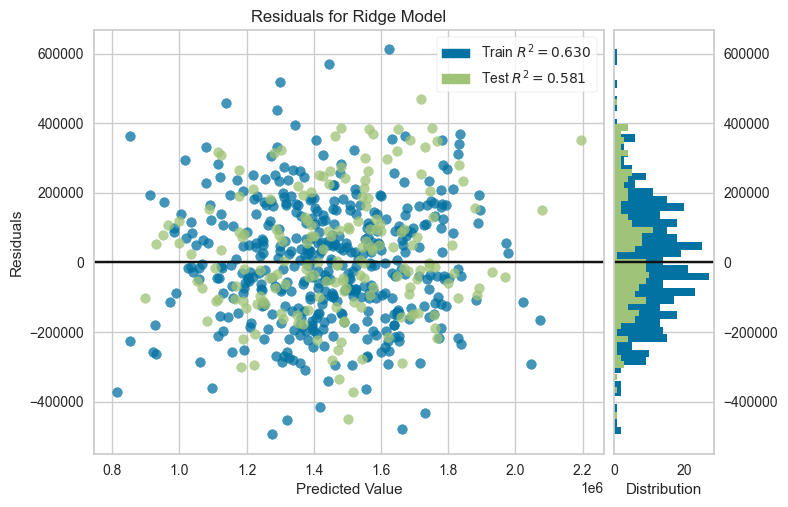

In [20]:
plot_model(ridge_model, plot="residuals")

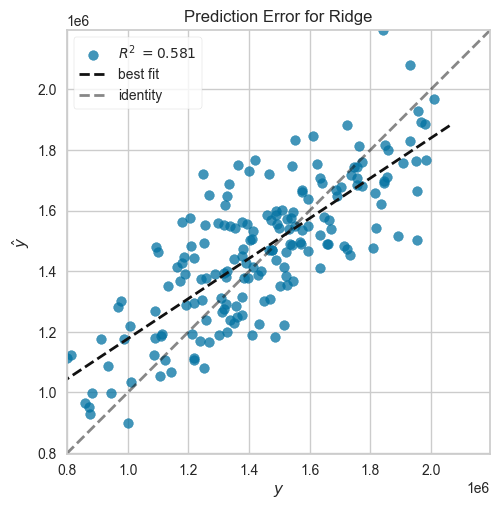

In [23]:
plot_model(ridge_model, plot="error")

In [25]:
#finalize the ridge model
final_ridge = finalize_model(ridge_model)

In [26]:
final_ridge

Pipeline(memory=Memory(location=None),
         steps=[('numerical_imputer',
                 TransformerWrapper(include=['area', 'bedrooms', 'bathrooms',
                                             'stories', 'parking'],
                                    transformer=SimpleImputer())),
                ('categorical_imputer',
                 TransformerWrapper(include=['mainroad', 'guestroom',
                                             'basement', 'hotwaterheating',
                                             'airconditioning', 'prefarea',
                                             'furnishingstatus'],
                                    transformer=SimpleImput...
                                                                         'data_type': dtype('O'),
                                                                         'mapping': no     0
yes    1
NaN   -1
dtype: int64},
                                                                        {'col': 'prefarea',
                                                                         'data_type': dtype('O'),
                                                                         'mapping': no     0
yes    1
NaN   -1
dtype: int64}]))),
                ('onehot_encoding',
                 TransformerWrapper(include=['furnishingstatus'],
                                    transformer=OneHotEncoder(cols=['furnishingstatus'],
                                                              handle_missing='return_nan',
                                                              use_cat_names=True))),
                ('actual_estimator', Ridge(random_state=42))])

In [27]:
#save the model
save_model(final_ridge, "house_price_ridge_model")

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(include=['area', 'bedrooms', 'bathrooms',
                                              'stories', 'parking'],
                                     transformer=SimpleImputer())),
                 ('categorical_imputer',
                  TransformerWrapper(include=['mainroad', 'guestroom',
                                              'basement', 'hotwaterheating',
                                              'airconditioning', 'prefarea',
                                              'furnishingstatus'],
                                     transformer=SimpleImput...
                                                                          'data_type': dtype('O'),
                                                                          'mapping': no     0
 yes    1
 NaN   -1
 dtype: int64},
                                                                         {'col'

In [28]:
#final prediction test.
loaded_model = load_model("house_price_ridge_model")

Transformation Pipeline and Model Successfully Loaded


In [29]:
loaded_model

Pipeline(memory=FastMemory(location=C:\Users\alluh\AppData\Local\Temp\joblib),
         steps=[('numerical_imputer',
                 TransformerWrapper(include=['area', 'bedrooms', 'bathrooms',
                                             'stories', 'parking'],
                                    transformer=SimpleImputer())),
                ('categorical_imputer',
                 TransformerWrapper(include=['mainroad', 'guestroom',
                                             'basement', 'hotwaterheating',
                                             'airconditioning', 'prefarea',
                                             'fu...
                                                                         'data_type': dtype('O'),
                                                                         'mapping': no     0
yes    1
NaN   -1
dtype: int64},
                                                                        {'col': 'prefarea',
                                                                         'data_type': dtype('O'),
                                                                         'mapping': no     0
yes    1
NaN   -1
dtype: int64}]))),
                ('onehot_encoding',
                 TransformerWrapper(include=['furnishingstatus'],
                                    transformer=OneHotEncoder(cols=['furnishingstatus'],
                                                              handle_missing='return_nan',
                                                              use_cat_names=True))),
                ('actual_estimator', Ridge(random_state=42))])

In [30]:
#predict a new house price
new_house = pd.DataFrame({
    "area": [3000],
    "bedrooms": [3],
    "bathrooms": [2],
    "stories": [2],
    "mainroad": ["yes"],
    "guestroom": ["no"],
    "basement": ["yes"],
    "hotwaterheating": ["no"],
    "airconditioning": ["yes"],
    "parking": [2],
    "prefarea": ["yes"],
    "furnishingstatus": ["semi-furnished"]
})

new_house

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,3000,3,2,2,yes,no,yes,no,yes,2,yes,semi-furnished


In [31]:
prediction = predict_model(loaded_model, data=new_house)

print(prediction.columns)
print(prediction)


Index(['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
       'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus', 'prediction_label'],
      dtype='object')
   area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  3000         3          2        2      yes        no      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  \
0              no             yes        2      yes   semi-furnished   

   prediction_label  
0      1.585142e+06  
